In [3]:
import yaml
import warnings

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as pl
import seaborn as sns
import PyComplexHeatmap as pch
from pathlib import Path
from tqdm.auto import tqdm

# make figures paper quality
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
# matplotlib.rcParams['font.family'] = 'Arial'

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']

In [5]:
seq_primer = config['primer_seq']  # sequence left of gRNA
guide_length = config['guide_length']
# primer will appear between min and max position
pmin, pmax = config['primer_range']['min'], config['primer_range']['max']

path = Path(config['TEMPDIR']) / 'pooled_screen_1/fastq'
data_path = Path(config['DATADIR'])

# Syntax: sym_cellline_replicate
cell_line_dict={
    '01': 'H1975',
    '02': 'H1299',
    '03': 'A549'
}
cell_lines = list(cell_line_dict.values())

# Target Alignment

In [7]:
def parse_sam_file(sam_file):
    data = []
    with open(sam_file, 'r') as f:
        for line in f:
            # Skip header lines if any
            if line.startswith('@'):
                continue
            
            fields = line.strip().split('\t')
            # Extract relevant fields
            query_name = fields[0]
            flag = int(fields[1])
            reference_name = fields[2]
            position = int(fields[3])
            mapq = int(fields[4])
            cigar = fields[5]
            rnext = fields[6]
            pnext = int(fields[7])
            tlen = int(fields[8])
            seq = fields[9]
            qual = fields[10]
            # Additional optional fields
            optional_fields = fields[11:]
            # Store the information
            data.append({'QueryName': query_name, 'Flag': flag, 'ReferenceName': reference_name, 'Position': position,
                         'MappingQuality': mapq, 'CIGAR': cigar, 'RNext': rnext, 'PNext': pnext, 'TLEN': tlen,
                         'Sequence': seq, 'Quality': qual, 'OptionalFields': optional_fields})
    return data

def process_alignment(sam_path, keep_duplicates=False):
    alignment = pd.DataFrame(parse_sam_file(sam_path)).set_index('QueryName')

    # Annotate strand
    alignment['strand'] = None
    alignment['strand'][(alignment['Flag'] == 16) | (alignment['Flag'] == 272)] = '-'
    alignment['strand'][(alignment['Flag'] == 0) | (alignment['Flag'] == 256)] = '+'
    # Remove and rename columns
    alignment.drop(['RNext', 'PNext', 'TLEN', 'OptionalFields'], inplace=True, axis=1)
    alignment.rename(columns={'ReferenceName': 'chromosome', 'Position': 'Start_position'}, inplace=True)
    alignment.index.name = 'guide_id'
    # Calculate end position
    alignment['End_position'] = alignment['Start_position'] + alignment['Sequence'].str.len()
    # Remove unmapped reads
    alignment = alignment[alignment['Flag'] != 4]

    alignment = alignment.sort_values('MappingQuality', ascending=False)
    salignment = alignment if keep_duplicates else alignment[~alignment.index.duplicated(keep='first')]
    guide_df = pd.read_csv('../resources/all_gRNA_data.csv', index_col='unique_guide_name')
    tab = pd.merge(guide_df, salignment, left_index=True, right_index=True, how='left')
    
    return tab

In [4]:
tab = process_alignment("/scratch/peidli/SYMPHONY/pooled_screen_1/hisat2/guides_aligned_to_genome.sam")
tab.to_csv('../resources/guide_alignment_dna_v1.csv')

tab_ = process_alignment("/scratch/peidli/SYMPHONY/pooled_screen_1/hisat2/guides_aligned_to_transcriptome.sam")
tab_.to_csv('../resources/guide_alignment_transcriptome_v1.csv')

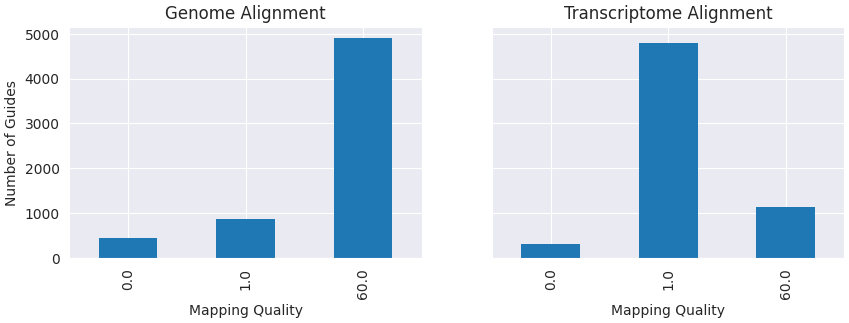

In [6]:
with sns.axes_style('darkgrid'):
    fig, axs = pl.subplots(1, 2, figsize=(10, 3), sharey=True)
ax = axs[0]
tab.MappingQuality.fillna(0).value_counts().sort_index().plot(kind='bar', ax=ax)
ax.set_title('Genome Alignment')
ax.set_ylabel('Number of Guides')

ax = axs[1]
tab_.MappingQuality.fillna(0).value_counts().sort_index().plot(kind='bar')
ax.set_title('Transcriptome Alignment')

for ax in axs:
    ax.set_xlabel('Mapping Quality')
    ax.grid(True)
pl.show()

In [8]:
# Keep multiple alignments
tab = process_alignment("/scratch/peidli/SYMPHONY/pooled_screen_1/hisat2/guides_aligned_to_genome.sam", True)
tab_ = process_alignment("/scratch/peidli/SYMPHONY/pooled_screen_1/hisat2/guides_aligned_to_transcriptome.sam", True)

In [9]:
tab_

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,...,transcript_per_gene,Flag,chromosome,Start_position,MappingQuality,CIGAR,Sequence,Quality,strand,End_position
AATBC_ENST00000400385_1005,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0983:983-1005,ACAGAACCCTAGGAAGCAACCTC,1005.0,0.789626,Gene_Body,4598.0,...,1,16.0,ENST00000400385.2|ENSG00000215458.8|OTTHUMG000...,983.0,60.0,23M,GAGGTTGCTTCCTAGGGTTCTGT,IIIIIIIIIIIIIIIIIIIIIII,-,1006.0
AATBC_ENST00000400385_1562,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1504:1540-1562,CCAGGCCACTTGCTCCACCCTCT,1562.0,0.747814,Gene_Body,4598.0,...,1,16.0,ENST00000400385.2|ENSG00000215458.8|OTTHUMG000...,1540.0,60.0,23M,AGAGGGTGGAGCAAGTGGCCTGG,IIIIIIIIIIIIIIIIIIIIIII,-,1563.0
AATBC_ENST00000400385_1938,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1862:1916-1938,TGACCTCTCACCCCGCAGCCTCT,1938.0,0.747682,Gene_Body,4598.0,...,1,16.0,ENST00000400385.2|ENSG00000215458.8|OTTHUMG000...,1916.0,60.0,23M,AGAGGCTGCGGGGTGAGAGGTCA,IIIIIIIIIIIIIIIIIIIIIII,-,1939.0
AATBC_ENST00000400385_2713,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA2601:2691-2713,CTGCCTTATAAAGATAGACCGGT,2713.0,0.870540,Gene_Body,4598.0,...,1,16.0,ENST00000400385.2|ENSG00000215458.8|OTTHUMG000...,2691.0,60.0,23M,ACCGGTCTATCTTTATAAGGCAG,IIIIIIIIIIIIIIIIIIIIIII,-,2714.0
AATBC_ENST00000400385_28,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0006:6-28,CCGGTCTCTGCAGTCACCCTCCT,28.0,0.762563,Gene_Body,4598.0,...,1,16.0,ENST00000400385.2|ENSG00000215458.8|OTTHUMG000...,6.0,60.0,23M,AGGAGGGTGACTGCAGAGACCGG,IIIIIIIIIIIIIIIIIIIIIII,-,29.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZSWIM3_ENST00000255152_164,ENST00000255152,ENSG00000132801,ZSWIM3,protein_coding,crRNA0142:142-164,CAAGATCACACCAGGGGTCAAAG,164.0,0.956957,UTR5,2776.0,...,1,16.0,ENST00000255152.3|ENSG00000132801.7|OTTHUMG000...,145.0,60.0,23M,CTTTGACCCCTGGTGTGATCTTG,IIIIIIIIIIIIIIIIIIIIIII,-,168.0
ZSWIM3_ENST00000255152_2431,ENST00000255152,ENSG00000132801,ZSWIM3,protein_coding,crRNA2370:2409-2431,TGTAACAATATTCCTAGCCCCAC,2431.0,1.329908,UTR3,2776.0,...,1,16.0,ENST00000255152.3|ENSG00000132801.7|OTTHUMG000...,2412.0,60.0,23M,GTGGGGCTAGGAATATTGTTACA,IIIIIIIIIIIIIIIIIIIIIII,-,2435.0
ZSWIM3_ENST00000255152_2528,ENST00000255152,ENSG00000132801,ZSWIM3,protein_coding,crRNA2467:2506-2528,TGAACAACAACTGAGGCTCCCAA,2528.0,1.386289,UTR3,2776.0,...,1,16.0,ENST00000255152.3|ENSG00000132801.7|OTTHUMG000...,2509.0,60.0,23M,TTGGGAGCCTCAGTTGTTGTTCA,IIIIIIIIIIIIIIIIIIIIIII,-,2532.0
ZSWIM3_ENST00000255152_32,ENST00000255152,ENSG00000132801,ZSWIM3,protein_coding,crRNA0010:10-32,GTTACAAGAGGAAGGGGGTGTAT,32.0,0.860280,UTR5,2776.0,...,1,16.0,ENST00000255152.3|ENSG00000132801.7|OTTHUMG000...,13.0,60.0,23M,ATACACCCCCTTCCTCTTGTAAC,IIIIIIIIIIIIIIIIIIIIIII,-,36.0


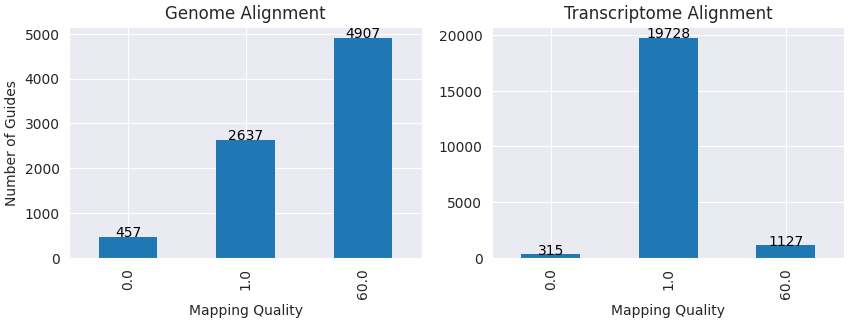

In [10]:
with sns.axes_style('darkgrid'):
    fig, axs = pl.subplots(1, 2, figsize=(10, 3), sharey=False)
ax = axs[0]
cts = tab.MappingQuality.fillna(0).value_counts().sort_index()
cts.plot(kind='bar', ax=ax)
ax.set_title('Genome Alignment')
ax.set_ylabel('Number of Guides')
# add values on top of bars
for i, v in enumerate(cts):
    ax.text(i, v + 10, str(v), color='black', ha='center')

ax = axs[1]
cts = tab_.MappingQuality.fillna(0).value_counts().sort_index()
cts.plot(kind='bar')
ax.set_title('Transcriptome Alignment')
# add values on top of bars
for i, v in enumerate(cts):
    ax.text(i, v + 10, str(v), color='black', ha='center')

for ax in axs:
    ax.set_xlabel('Mapping Quality')
    ax.grid(True)
pl.show()

In [11]:
dup_idxs = pd.unique(tab_.index[tab_.index.duplicated()])

In [12]:
# Revelation: the last str ing guide name is position. More clearly defined in "GuideName" e.g. crRNA3261:3378-3400	goes from 3378 to 3400 (+1 for 1-based indexing apparently)
tab_.loc[[dup_idxs[0]]]

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,...,transcript_per_gene,Flag,chromosome,Start_position,MappingQuality,CIGAR,Sequence,Quality,strand,End_position
AATBC_ENST00000400385_3400,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA3261:3378-3400,TCAGAGCTTCAGTAGCAACCCAC,3400.0,0.88304,Gene_Body,4598.0,...,1,272.0,ENST00000400385.2|ENSG00000215458.8|OTTHUMG000...,3378.0,1.0,23M,GTGGGTTGCTACTGAAGCTCTGA,IIIIIIIIIIIIIIIIIIIIIII,-,3401.0
AATBC_ENST00000400385_3400,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA3261:3378-3400,TCAGAGCTTCAGTAGCAACCCAC,3400.0,0.88304,Gene_Body,4598.0,...,1,16.0,ENST00000448247.5|ENSG00000215458.8|OTTHUMG000...,393.0,1.0,23M,GTGGGTTGCTACTGAAGCTCTGA,IIIIIIIIIIIIIIIIIIIIIII,-,416.0


So there is multiple matches! I should check if there might be a PAM or similar involved.

In [13]:
tab.loc[[dup_idxs[0]]]

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,...,transcript_per_gene,Flag,chromosome,Start_position,MappingQuality,CIGAR,Sequence,Quality,strand,End_position
AATBC_ENST00000400385_3400,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA3261:3378-3400,TCAGAGCTTCAGTAGCAACCCAC,3400.0,0.88304,Gene_Body,4598.0,...,1,0.0,21,43809168.0,60.0,23M,TCAGAGCTTCAGTAGCAACCCAC,IIIIIIIIIIIIIIIIIIIIIII,+,43809191.0


Ok, let's quantify how many guide have multiple alignments, if they are in the same gene, and if one of them matches the site given in "GuideName".

In [14]:
# Step 1: extract the guide name and position
# Step 2: check if any alignment matches the given position
# Step 3: make a barplot I guess, grouping by number of alignments and matching y/n

In [19]:
tab_

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,...,transcript_per_gene,Flag,chromosome,Start_position,MappingQuality,CIGAR,Sequence,Quality,strand,End_position
AATBC_ENST00000400385_1005,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0983:983-1005,ACAGAACCCTAGGAAGCAACCTC,1005.0,0.789626,Gene_Body,4598.0,...,1,16.0,ENST00000400385.2|ENSG00000215458.8|OTTHUMG000...,983.0,60.0,23M,GAGGTTGCTTCCTAGGGTTCTGT,IIIIIIIIIIIIIIIIIIIIIII,-,1006.0
AATBC_ENST00000400385_1562,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1504:1540-1562,CCAGGCCACTTGCTCCACCCTCT,1562.0,0.747814,Gene_Body,4598.0,...,1,16.0,ENST00000400385.2|ENSG00000215458.8|OTTHUMG000...,1540.0,60.0,23M,AGAGGGTGGAGCAAGTGGCCTGG,IIIIIIIIIIIIIIIIIIIIIII,-,1563.0
AATBC_ENST00000400385_1938,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1862:1916-1938,TGACCTCTCACCCCGCAGCCTCT,1938.0,0.747682,Gene_Body,4598.0,...,1,16.0,ENST00000400385.2|ENSG00000215458.8|OTTHUMG000...,1916.0,60.0,23M,AGAGGCTGCGGGGTGAGAGGTCA,IIIIIIIIIIIIIIIIIIIIIII,-,1939.0
AATBC_ENST00000400385_2713,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA2601:2691-2713,CTGCCTTATAAAGATAGACCGGT,2713.0,0.870540,Gene_Body,4598.0,...,1,16.0,ENST00000400385.2|ENSG00000215458.8|OTTHUMG000...,2691.0,60.0,23M,ACCGGTCTATCTTTATAAGGCAG,IIIIIIIIIIIIIIIIIIIIIII,-,2714.0
AATBC_ENST00000400385_28,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0006:6-28,CCGGTCTCTGCAGTCACCCTCCT,28.0,0.762563,Gene_Body,4598.0,...,1,16.0,ENST00000400385.2|ENSG00000215458.8|OTTHUMG000...,6.0,60.0,23M,AGGAGGGTGACTGCAGAGACCGG,IIIIIIIIIIIIIIIIIIIIIII,-,29.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZSWIM3_ENST00000255152_164,ENST00000255152,ENSG00000132801,ZSWIM3,protein_coding,crRNA0142:142-164,CAAGATCACACCAGGGGTCAAAG,164.0,0.956957,UTR5,2776.0,...,1,16.0,ENST00000255152.3|ENSG00000132801.7|OTTHUMG000...,145.0,60.0,23M,CTTTGACCCCTGGTGTGATCTTG,IIIIIIIIIIIIIIIIIIIIIII,-,168.0
ZSWIM3_ENST00000255152_2431,ENST00000255152,ENSG00000132801,ZSWIM3,protein_coding,crRNA2370:2409-2431,TGTAACAATATTCCTAGCCCCAC,2431.0,1.329908,UTR3,2776.0,...,1,16.0,ENST00000255152.3|ENSG00000132801.7|OTTHUMG000...,2412.0,60.0,23M,GTGGGGCTAGGAATATTGTTACA,IIIIIIIIIIIIIIIIIIIIIII,-,2435.0
ZSWIM3_ENST00000255152_2528,ENST00000255152,ENSG00000132801,ZSWIM3,protein_coding,crRNA2467:2506-2528,TGAACAACAACTGAGGCTCCCAA,2528.0,1.386289,UTR3,2776.0,...,1,16.0,ENST00000255152.3|ENSG00000132801.7|OTTHUMG000...,2509.0,60.0,23M,TTGGGAGCCTCAGTTGTTGTTCA,IIIIIIIIIIIIIIIIIIIIIII,-,2532.0
ZSWIM3_ENST00000255152_32,ENST00000255152,ENSG00000132801,ZSWIM3,protein_coding,crRNA0010:10-32,GTTACAAGAGGAAGGGGGTGTAT,32.0,0.860280,UTR5,2776.0,...,1,16.0,ENST00000255152.3|ENSG00000132801.7|OTTHUMG000...,13.0,60.0,23M,ATACACCCCCTTCCTCTTGTAAC,IIIIIIIIIIIIIIIIIIIIIII,-,36.0


In [43]:
tab_['GuideName_start'] = tab_.GuideName.str.split(':').str[1].str.split('-').str[0]
tab_['GuideName_end'] = tab_.GuideName.str.split(':').str[1].str.split('-').str[1]
tab_.GuideName_start = [int(x) if x == x else np.nan for x in tab_.GuideName_start]
tab_.GuideName_end = [int(x)+1 if x == x else np.nan for x in tab_.GuideName_end]
tab_['offset'] = tab_.GuideName_start - tab_.Start_position
tab_['alignment_type'] = ['None' if flag!=flag else 'primary' if flag <=16 else 'secondary' for flag in tab_.Flag]

<Axes: xlabel='offset', ylabel='Count'>

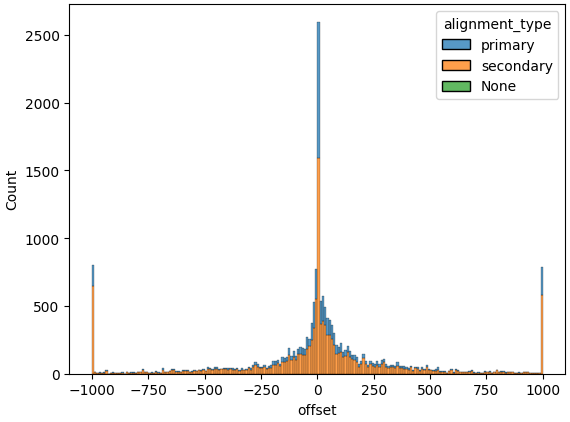

In [60]:
n_clip = 1000
df = tab_.copy()
df.offset = df.offset.clip(-n_clip, n_clip)
df.reset_index(inplace=True)
sns.histplot(data=df, x='offset', bins=200, hue='alignment_type', multiple='stack')


In [81]:
tab_['alignment_transcript_id'] = ['None' if chrom!=chrom else chrom.split('|')[0].split('.')[0] for chrom in tab_.chromosome]
tab_['alignment_transcript_match'] = tab_.alignment_transcript_id == tab_.Transcript_ID

<Axes: xlabel='offset', ylabel='Count'>

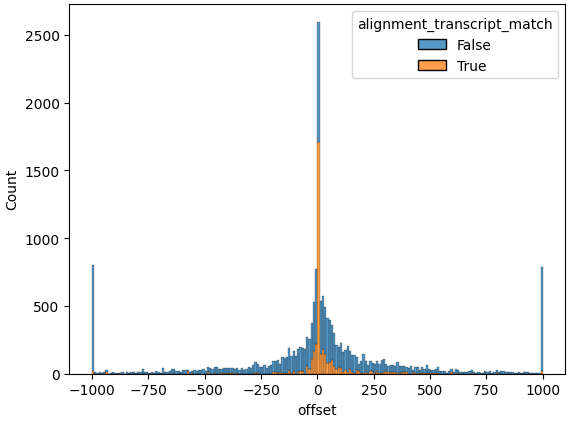

In [82]:
n_clip = 1000
df = tab_.copy()
df.offset = df.offset.clip(-n_clip, n_clip)
df.reset_index(inplace=True)
sns.histplot(data=df, x='offset', bins=200, hue='alignment_transcript_match', multiple='stack')


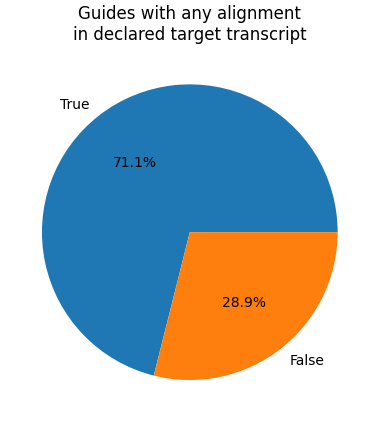

In [92]:
# How many guide have alignments in the target transcript?
cts = tab_['alignment_transcript_match'].groupby(tab_.index).max().value_counts()
pl.pie(cts, labels=cts.index, autopct='%1.1f%%')
pl.title('Guides with any alignment\nin declared target transcript')
pl.show()

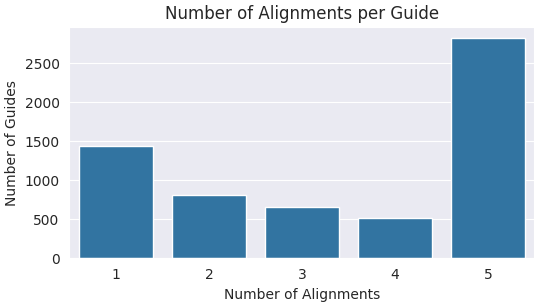

In [103]:
# How many guide have multiple alignments?
cts = tab_.groupby(tab_.index).size().value_counts().sort_index()

with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(6, 3))
    sns.barplot(x=cts.index, y=cts, color='tab:blue', ax=ax)
pl.xlabel('Number of Alignments')
pl.ylabel('Number of Guides')
pl.title('Number of Alignments per Guide')
pl.show()

# CIRCOS plots

In [3]:
import pycircos
import collections
cell_lines = ['H1975', 'H1299', 'A549']

In [4]:
cell_line = cell_lines[1]
segments = pd.read_csv(f'/scratch/peidli/SYMPHONY/pooled_screen_1/crisprcleanr/{cell_line}_segments.csv', index_col=0)
corr_lfc = pd.read_csv(f'/scratch/peidli/SYMPHONY/pooled_screen_1/crisprcleanr/{cell_line}_corrected_logFCs.csv', index_col=0)
corr_lfc

,CHR,startp,endp,genes,avgFC,BP,correction,correctedFC,guideIdx
ATAD3B_ENST00000308647_1564,1,1490367,1490390,ATAD3B,-0.789646,1490378.5,-1,-0.635977,1
ATAD3B_ENST00000308647_1568,1,1490371,1490394,ATAD3B,-1.252854,1490382.5,-1,-1.099185,2
ATAD3B_ENST00000308647_1571,1,1490374,1490397,ATAD3B,-1.618066,1490385.5,-1,-1.464397,3
ATAD3B_ENST00000308647_2408,1,1496162,1496185,ATAD3B,0.249316,1496173.5,-1,0.402985,4
ATAD3B_ENST00000308647_2410,1,1496164,1496187,ATAD3B,0.245455,1496175.5,-1,0.399124,5
...,...,...,...,...,...,...,...,...,...
TMLHE_ENST00000334398_462,23,155524498,155524521,TMLHE,0.129090,155524509.5,1,0.390070,143
TMLHE_ENST00000369439_45,23,155612833,155612856,TMLHE,0.323944,155612844.5,1,0.584925,144
TMLHE_ENST00000369439_44,23,155612834,155612857,TMLHE,-0.129326,155612845.5,1,0.131655,145
TMLHE_ENST00000334398_43,23,155612894,155612917,TMLHE,0.547325,155612905.5,1,0.808305,146


In [185]:
def circos_plot(ccr_segments, cnv_segments, ccr_lfc, save_as, show=True):
    #Set chromosomes
    Garc    = pycircos.Garc
    Gcircle = pycircos.Gcircle
    circle = Gcircle(figsize=(8,8)) 
    with open("../utils/pycircos_example_data_chromosome_general.csv") as f:
        f.readline()
        for line in f:
            line   = line.rstrip().split(",") 
            name   = line[0]
            length = int(line[-1]) 
            arc    = Garc(arc_id=name, size=length, interspace=2, raxis_range=(800,850), labelposition=80, label_visible=True)
            circle.add_garc(arc)
    circle.set_garcs(0,360) 

    #bar plot for segments
    values_all   = [] 
    arcdata_dict = collections.defaultdict(dict)
    with open(ccr_segments) as f:
        f.readline()
        for line in f:
            line  = line.rstrip().split(",")
            name  = 'chr' + line[1] if int(line[1]) < 23 else 'chrX' if int(line[1]) == 23 else 'chrY'
            start = int(line[2])-1
            end   = int(line[3]) 
            width = end-start
            # skip small segments
            if int(line[4]) <= 21:
                continue
            if name not in arcdata_dict:
                arcdata_dict[name]["positions"] = []
                arcdata_dict[name]["widths"]    = [] 
                arcdata_dict[name]["values"]    = [] 
            arcdata_dict[name]["positions"].append(start) 
            arcdata_dict[name]["widths"].append(width)
            arcdata_dict[name]["values"].append(float(line[5]))
            values_all.append(float(line[5]))
    m = np.max(np.abs(values_all))
    for key in arcdata_dict:  
        circle.barplot(key, 
                    data=arcdata_dict[key]["values"], 
                    positions=arcdata_dict[key]["positions"], 
                    width=arcdata_dict[key]["widths"], 
                    base_value=0.0, 
                    rlim=[-m, m],
                    raxis_range=[600,800], 
                    facecolor="r", spine=True)
    
    # CNV profile from WESeq
    values_all   = [] 
    arcdata_dict = collections.defaultdict(dict)
    with open(cnv_segments) as f:
        f.readline()
        for line in f:
            line  = line.rstrip().split(",")
            name  = line[2]
            start = int(line[3])-1
            end   = int(line[4]) 
            width = end-start 
            if name not in arcdata_dict:
                arcdata_dict[name]["positions"] = []
                arcdata_dict[name]["widths"]    = [] 
                arcdata_dict[name]["values"]    = [] 
            arcdata_dict[name]["positions"].append(start) 
            arcdata_dict[name]["widths"].append(width)
            val = float(line[6]) if line[6] != '' else 2.0
            arcdata_dict[name]["values"].append(val)
            values_all.append(val)
    m = np.max(np.abs(values_all))
    for key in arcdata_dict:  
        circle.barplot(key, 
                    data=arcdata_dict[key]["values"], 
                    positions=arcdata_dict[key]["positions"], 
                    width=arcdata_dict[key]["widths"], 
                    base_value=0.0, 
                    rlim=[-m, m],
                    raxis_range=[400,600], 
                    facecolor="b", spine=True)
        
    #scatter plot for lfcs
    values_all   = [] 
    arcdata_dict = collections.defaultdict(dict)
    with open(ccr_lfc) as f:
        f.readline()
        for line in f:
            line  = line.rstrip().split(",")
            name  = 'chr' + line[1] if int(line[1]) < 23 else 'chrX' if int(line[1]) == 23 else 'chrY'
            start = int(line[2])-1
            end   = int(line[3]) 
            mid   = (start+end)/2
            value = float(line[5]) 
            values_all.append(value) 
            if name not in arcdata_dict:
                arcdata_dict[name]["positions"] = []
                arcdata_dict[name]["values"] = []
            arcdata_dict[name]["positions"].append(mid) 
            arcdata_dict[name]["values"].append(value)
    vmin, vmax = min(values_all), max(values_all) 
    for key in arcdata_dict:
        circle.scatterplot(key, 
                        data=arcdata_dict[key]["values"], 
                        positions=arcdata_dict[key]["positions"], 
                        rlim=[vmin-0.05*abs(vmin), vmax+0.05*abs(vmax)], 
                        raxis_range=(200,400), 
                        facecolor="green", spine=True) 

    pl.title('CRISPRcleanR Copynumber Effect Assessment for ' + cell_line +'\nred=CN segments, blue=WESeq CNs, green=uncorrected lfc', fontsize=20)
    pl.savefig(save_as, bbox_inches='tight')
    if show: pl.show()

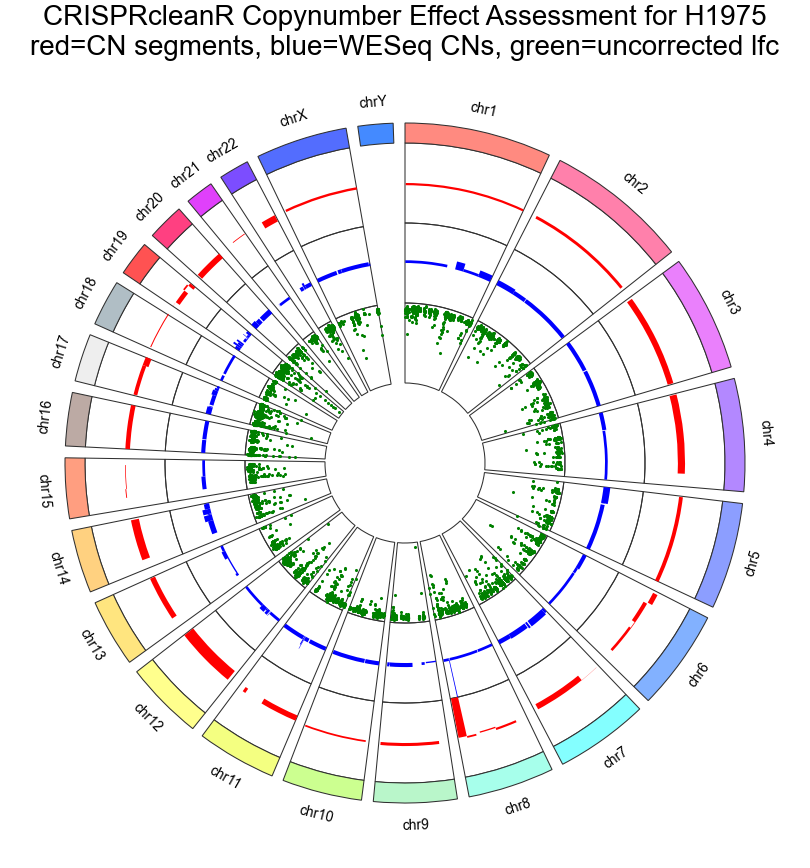

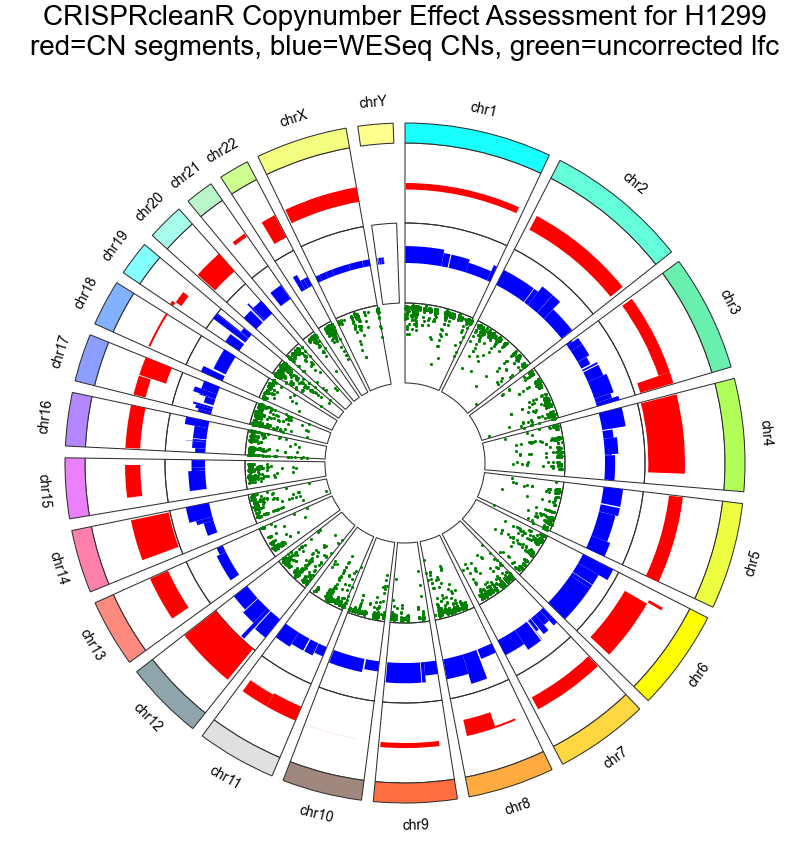

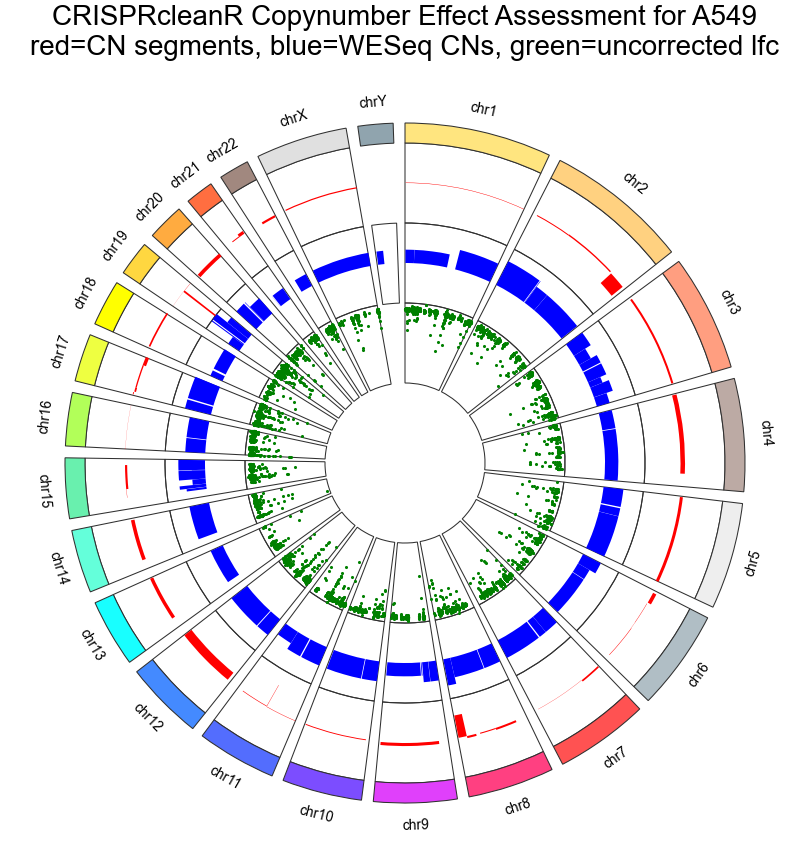

In [186]:
for cell_line in cell_lines:
    ccr_segments = f'/scratch/peidli/SYMPHONY/pooled_screen_1/crisprcleanr/{cell_line}_segments.csv'
    cnv_segments = f'../resources/CNV_profiles/{cell_line}_pureCN_CNV_segments.csv'
    ccr_lfc = f'/scratch/peidli/SYMPHONY/pooled_screen_1/crisprcleanr/{cell_line}_corrected_logFCs.csv'
    save_as = f'../results/copynumber/crisprcleanr_{cell_line}.pdf'
    circos_plot(ccr_segments, cnv_segments, ccr_lfc, save_as, show=True)

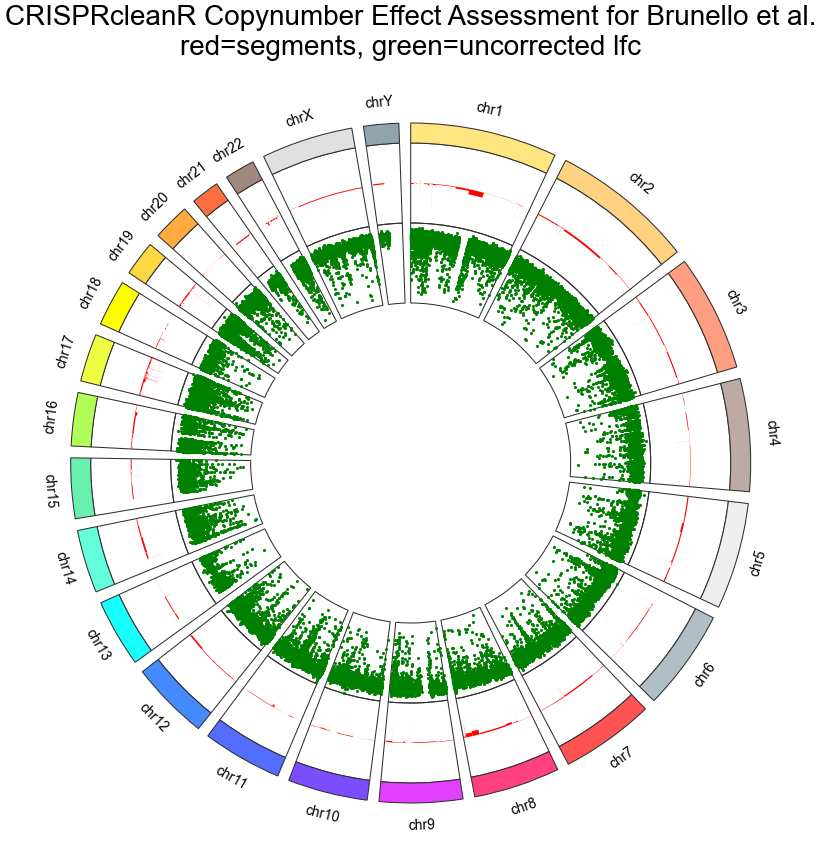

In [13]:
#Set chromosomes
Garc    = pycircos.Garc
Gcircle = pycircos.Gcircle
circle = Gcircle(figsize=(8,8)) 
with open("../utils/pycircos_example_data_chromosome_general.csv") as f:
    f.readline()
    for line in f:
        line   = line.rstrip().split(",") 
        name   = line[0]
        length = int(line[-1]) 
        arc    = Garc(arc_id=name, size=length, interspace=2, raxis_range=(800,850), labelposition=80, label_visible=True)
        circle.add_garc(arc)
circle.set_garcs(0,360) 

#bar plot for segments
values_all   = [] 
arcdata_dict = collections.defaultdict(dict)
with open(f'/scratch/peidli/SYMPHONY/pooled_screen_1/crisprcleanr/example_Brunello/HT29_segments.csv') as f:
    f.readline()
    for line in f:
        line  = line.rstrip().split(",")
        name  = 'chr' + line[1] if int(line[1]) < 23 else 'chrX' if int(line[1]) == 23 else 'chrY'
        start = int(line[2])-1
        end   = int(line[3]) 
        width = end-start 
        if name not in arcdata_dict:
            arcdata_dict[name]["positions"] = []
            arcdata_dict[name]["widths"]    = [] 
            arcdata_dict[name]["values"]    = [] 
        arcdata_dict[name]["positions"].append(start) 
        arcdata_dict[name]["widths"].append(width)
        arcdata_dict[name]["values"].append(float(line[5]))
        values_all.append(float(line[5]))
m = np.max(np.abs(values_all))
for key in arcdata_dict:  
    circle.barplot(key, 
                data=arcdata_dict[key]["values"], 
                positions=arcdata_dict[key]["positions"], 
                width=arcdata_dict[key]["widths"], 
                base_value=0.0, 
                rlim=[-m, m],
                raxis_range=[600,800], 
                facecolor="r", spine=True)
    
#scatter plot for lfcs
values_all   = [] 
arcdata_dict = collections.defaultdict(dict)
with open(f'/scratch/peidli/SYMPHONY/pooled_screen_1/crisprcleanr/example_Brunello/HT29_corrected_logFCs.csv') as f:
    f.readline()
    for line in f:
        line  = line.rstrip().split(",")
        name  = 'chr' + line[1] if int(line[1]) < 23 else 'chrX' if int(line[1]) == 23 else 'chrY'
        start = int(float(line[2]))-1
        end   = int(line[3]) 
        mid   = (start+end)/2
        value = float(line[5]) 
        values_all.append(value) 
        if name not in arcdata_dict:
            arcdata_dict[name]["positions"] = []
            arcdata_dict[name]["values"] = []
        arcdata_dict[name]["positions"].append(mid) 
        arcdata_dict[name]["values"].append(value)
vmin, vmax = min(values_all), max(values_all) 
for key in arcdata_dict:
    circle.scatterplot(key, 
                    data=arcdata_dict[key]["values"], 
                    positions=arcdata_dict[key]["positions"], 
                    rlim=[vmin-0.05*abs(vmin), vmax+0.05*abs(vmax)], 
                    raxis_range=(400,600), 
                    facecolor="green", spine=True) 

pl.title('CRISPRcleanR Copynumber Effect Assessment for Brunello et al.\nred=segments, green=uncorrected lfc', fontsize=20)
pl.savefig(f'../results/copynumber/crisprcleanr_Brunello.pdf', bbox_inches='tight')
pl.show()

In [ ]:
# Next steps?
# Exclude essential genes?

# Maybe another view will clear things up

In [6]:
# load data
cell_line = cell_lines[1]
ccr_segments = pd.read_csv(f'/scratch/peidli/SYMPHONY/pooled_screen_1/crisprcleanr/{cell_line}_segments.csv', index_col=0)
cnv_segments = pd.read_csv(f'../resources/CNV_profiles/{cell_line}_pureCN_CNV_segments.csv')
ccr_lfc = pd.read_csv(f'/scratch/peidli/SYMPHONY/pooled_screen_1/crisprcleanr/{cell_line}_corrected_logFCs.csv', index_col=0)

In [7]:
# find chromosomes with multiple segments
nsegs = ccr_segments.groupby('CHR').size().sort_values(ascending=False)
chroms = list(nsegs[nsegs>1].index)

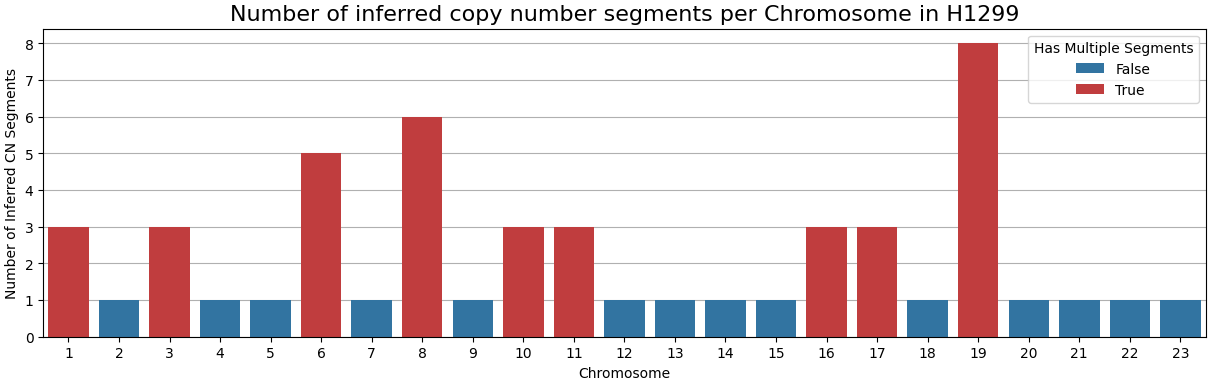

In [8]:
pl.figure(figsize=(15, 4))
pl.grid(axis='y')
data = nsegs.reset_index()
# sort data numerically by chromosome
data = data.sort_values('CHR')
data['has_segment'] = data.CHR.isin(chroms)
# get number of guides per segment
sns.barplot(data=data, x='CHR', y=0, zorder=2, hue='has_segment', dodge=False, palette={True: 'tab:red', False: 'tab:blue'})
pl.ylabel('Number of Inferred CN Segments')
pl.xlabel('Chromosome')
pl.legend(title=f'Has Multiple Segments', loc='upper right')
pl.title(f'Number of inferred copy number segments per Chromosome in {cell_line}', fontsize=16)
pl.savefig(f'../results/copynumber/segments_per_chromosome_{cell_line}.pdf', bbox_inches='tight')
pl.show()

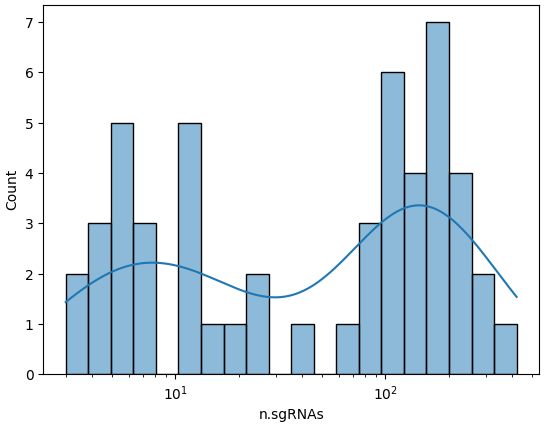

In [9]:
# Some segments contain very few guides, despite setting nmin_genes to 21
sns.histplot(data=ccr_segments, x='n.sgRNAs', bins=20, kde=True, log_scale=True)
pl.show()

In [10]:
# Let's remove them
ccr_segments = ccr_segments[ccr_segments['n.sgRNAs'] >= 21].copy()

In [11]:
# Let's correlate the CNV segments with the CRISPRcleanR segments
# Specifically look at the "avg.logFC" in CRISPRcleanR and the "total_copy_number" in the CNV segments

# Overlap of CNV segments with CRISPRcleanR segments
overlaps = {}
for index, row in ccr_segments.iterrows():
    chrom, start, end = row['CHR'], row['startp'], row['endp']
    overlap = cnv_segments[(cnv_segments.chr_name == f'chr{chrom}') & (cnv_segments.chr_start <= end) & (cnv_segments.chr_end >= start)]
    overlaps[index] = list(overlap.index)

In [12]:
# multiple CNV segments can overlap with one CRISPRcleanR segment. How to merge?
# For now, just take the first one
dats = []
for key, value in overlaps.items():
    if len(value) > 0:
        dats.append([key, value[0], ccr_segments.loc[key, 'CHR'], cnv_segments.loc[value[0], 'total_copy_number'], ccr_segments.loc[key, 'avg.logFC']])

In [13]:
tab = pd.DataFrame(dats, columns=['ccr_segment', 'cnv_segment', 'chromosome', 'total_copy_number', 'avg.logFC'])
tab.total_copy_number = tab.total_copy_number.astype(int)

In [17]:
tab.head()

,ccr_segment,cnv_segment,chromosome,total_copy_number,avg.logFC
0,1,25,1,3,-0.1152
1,4,5,2,5,-0.2765
2,5,1,3,4,-0.2095
3,7,19,3,5,-0.6091
4,8,2,4,3,-0.6484


In [15]:
tab

,ccr_segment,cnv_segment,chromosome,total_copy_number,avg.logFC
0,1,25,1,3,-0.1152
1,4,5,2,5,-0.2765
2,5,1,3,4,-0.2095
3,7,19,3,5,-0.6091
4,8,2,4,3,-0.6484
5,9,0,5,5,-0.2476
6,12,35,6,10,0.2775
7,14,82,6,7,-0.4533
8,15,4,7,5,-0.2405
9,16,33,8,3,-0.0350


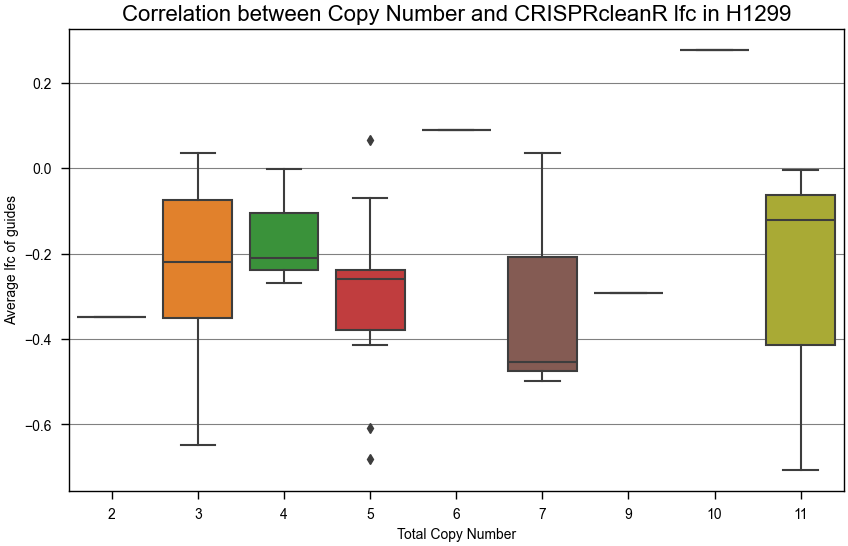

In [31]:
fig, ax = pl.subplots(figsize=(10, 6))
sns.boxplot(data=tab, x='total_copy_number', y='avg.logFC', dodge=False, zorder=1000, ax=ax)
ax.set_axisbelow(True)
ax.yaxis.grid(color='gray')
pl.ylabel('Average lfc of guides')
pl.xlabel('Total Copy Number')
pl.title(f'Correlation between Copy Number and CRISPRcleanR lfc in {cell_line}', fontsize=16)
pl.savefig(f'../results/copynumber/cnv_vs_lfc_{cell_line}.pdf', bbox_inches='tight')
pl.show()

  0%|          | 0/23 [00:00<?, ?it/s]

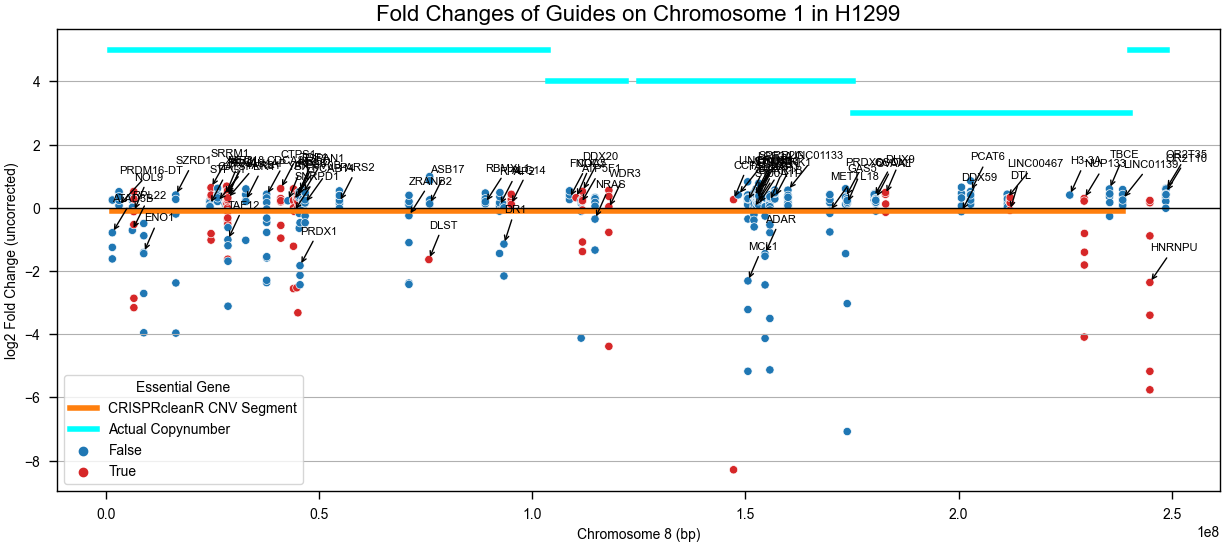

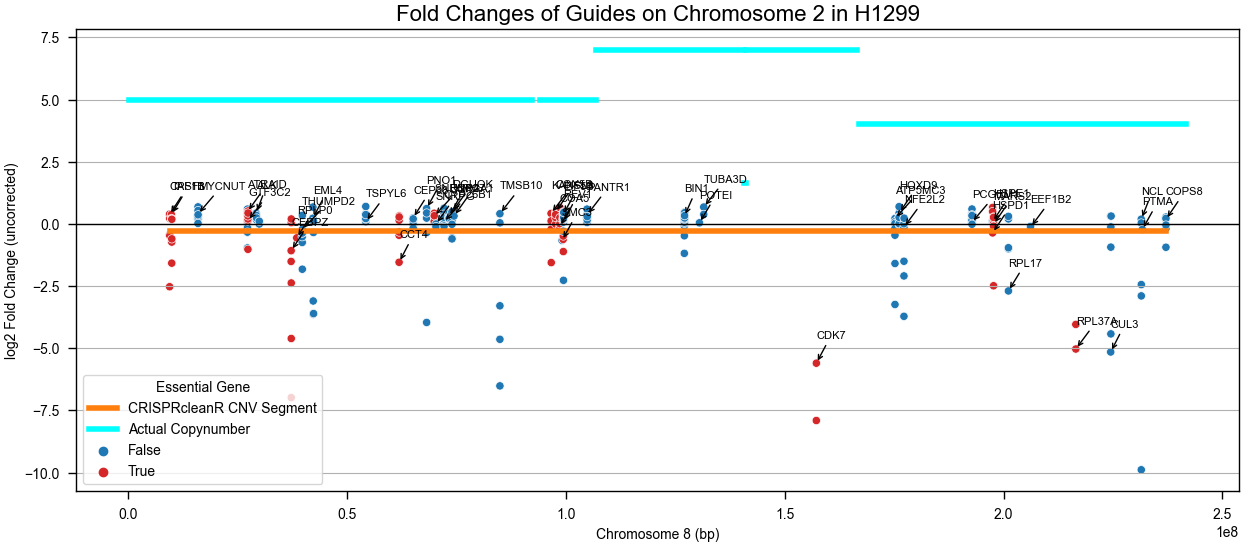

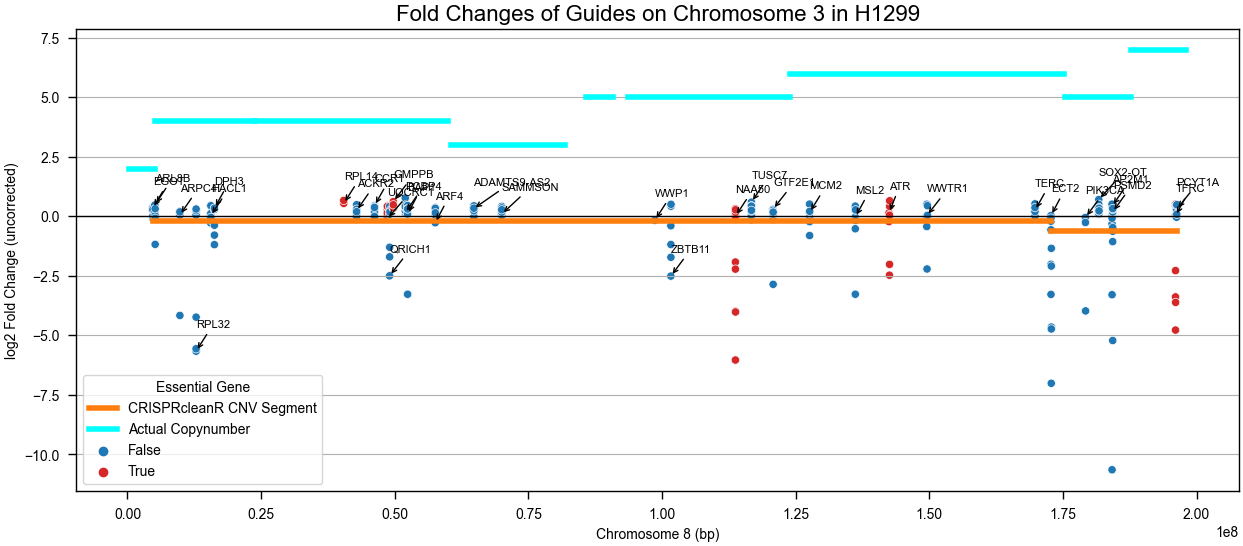

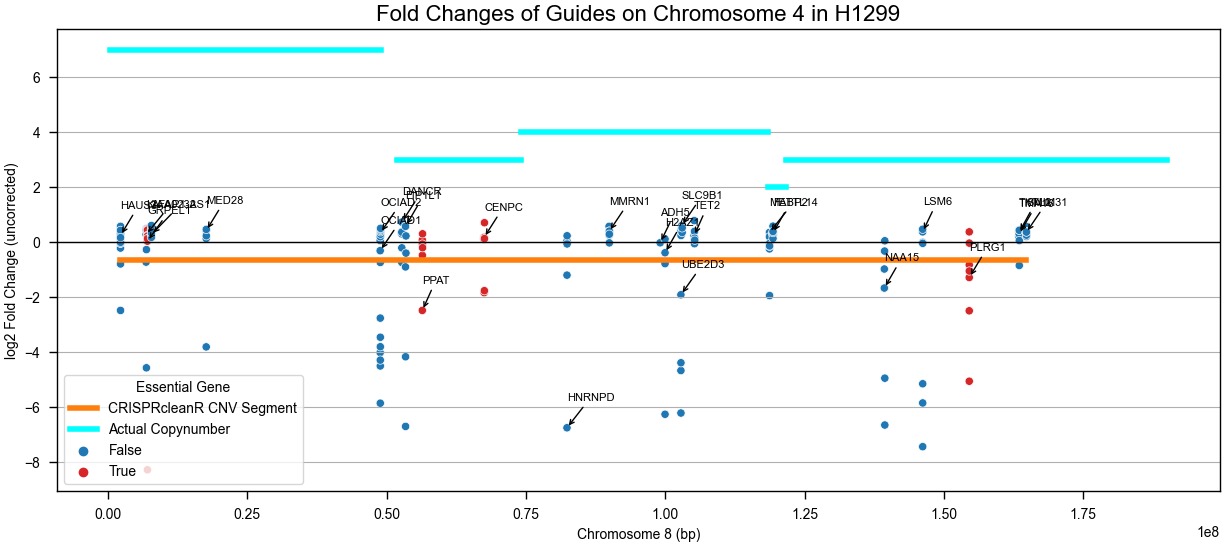

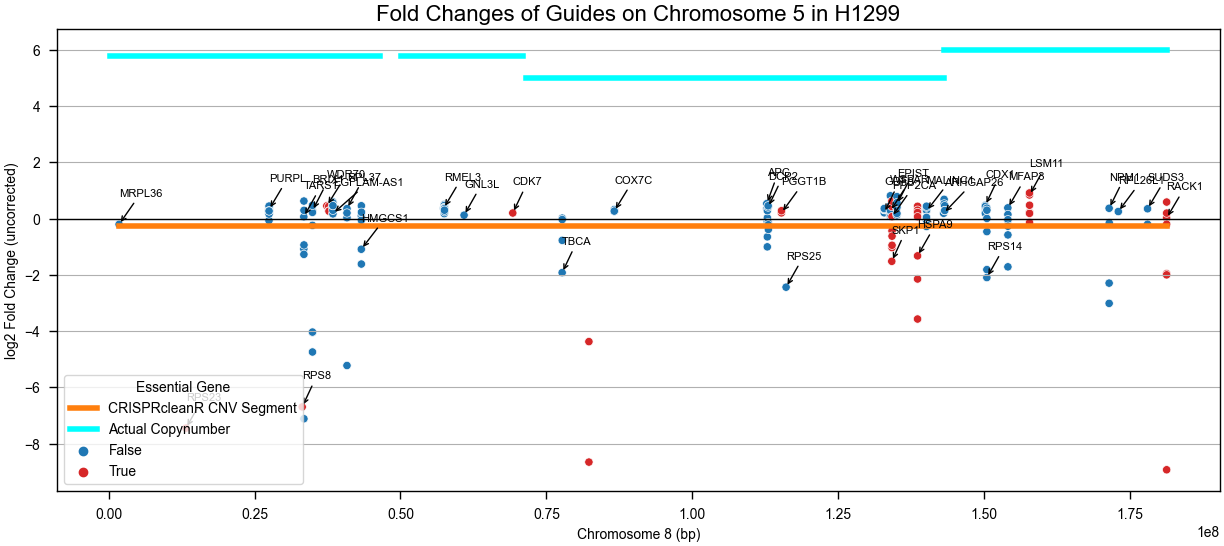

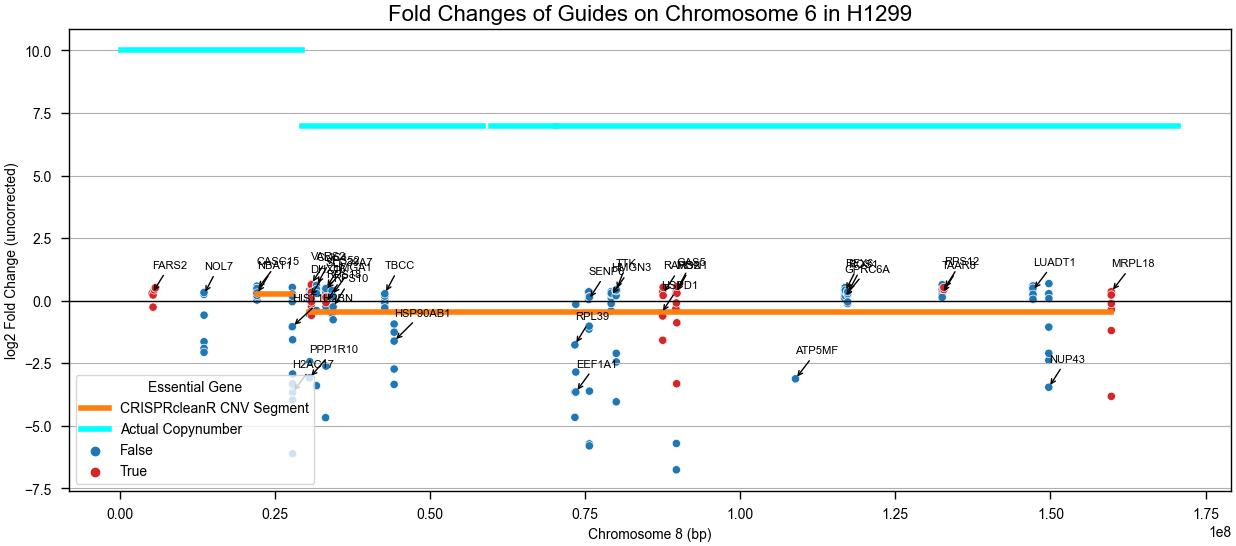

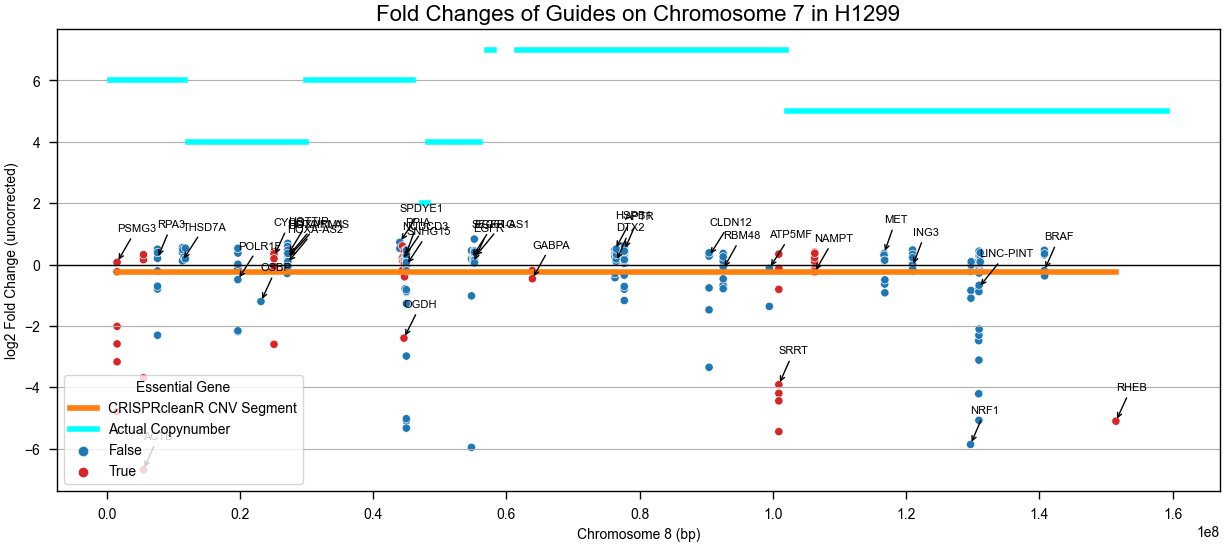

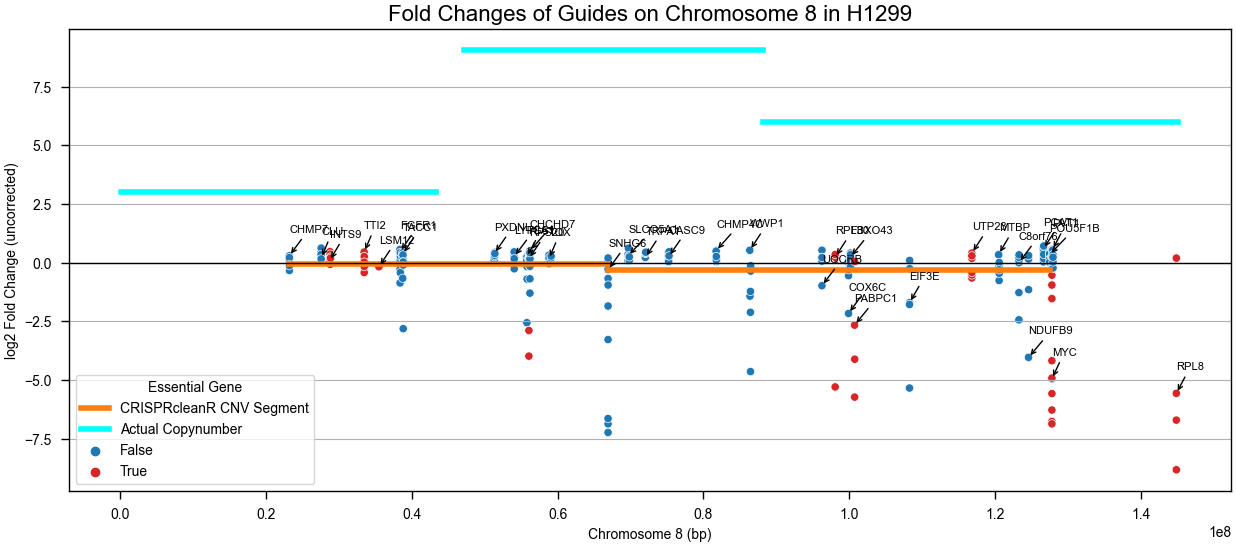

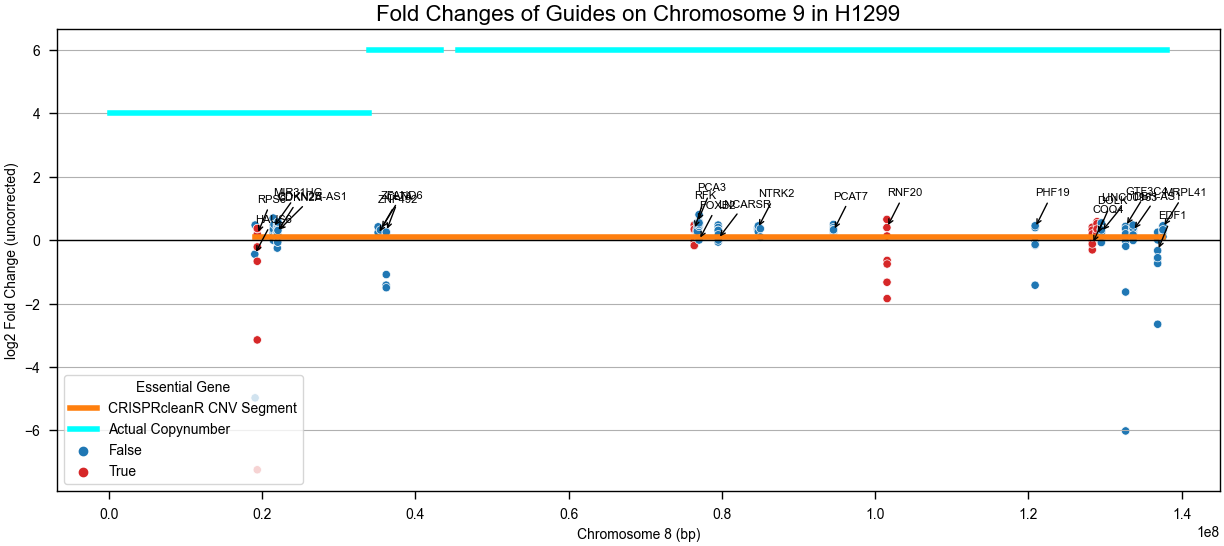

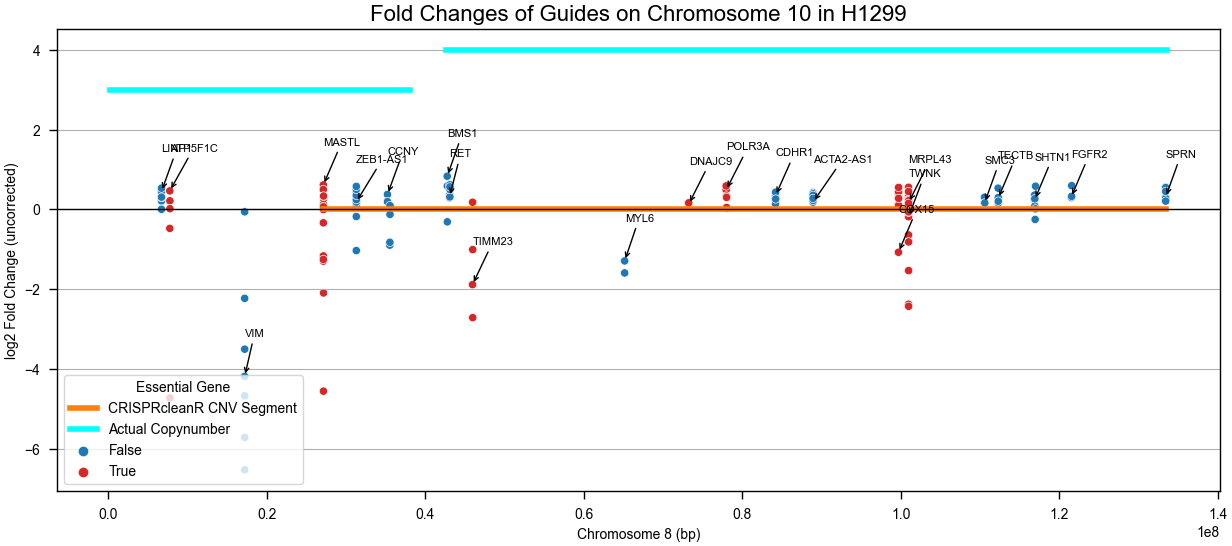

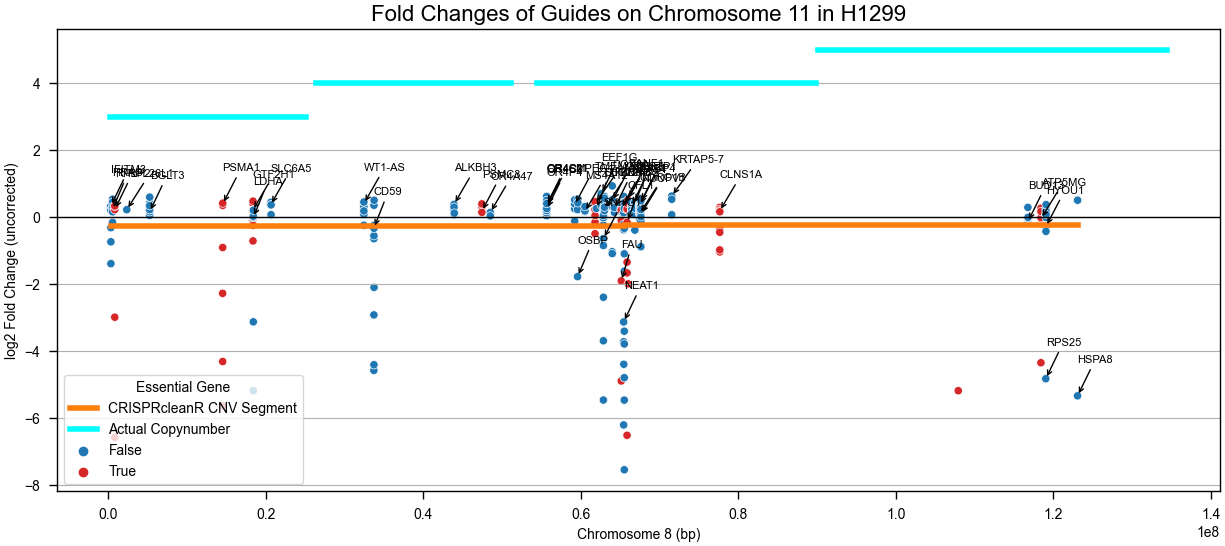

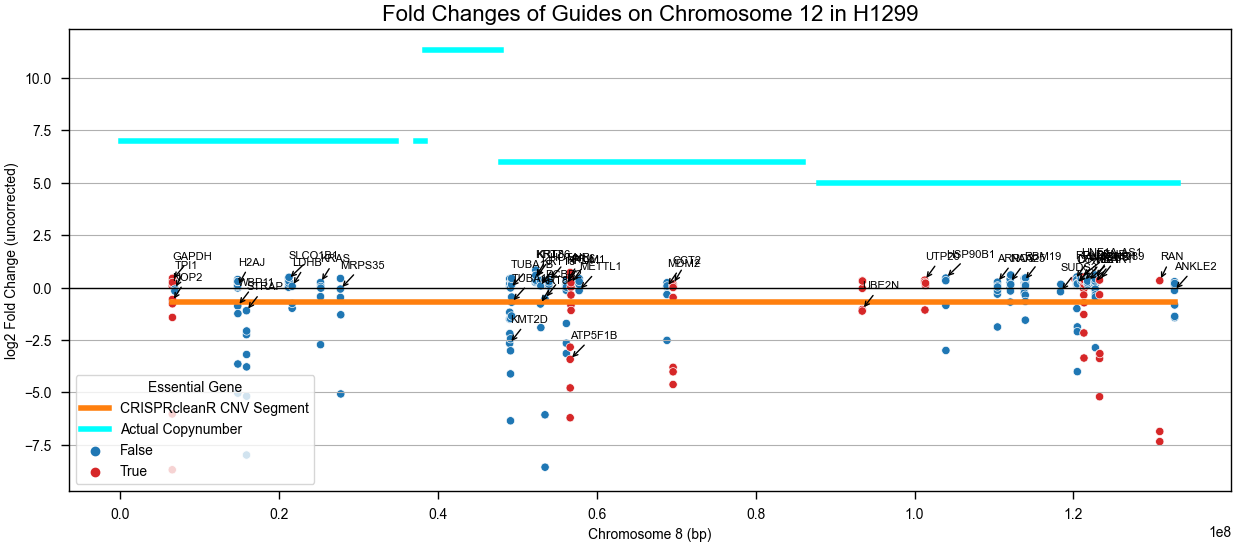

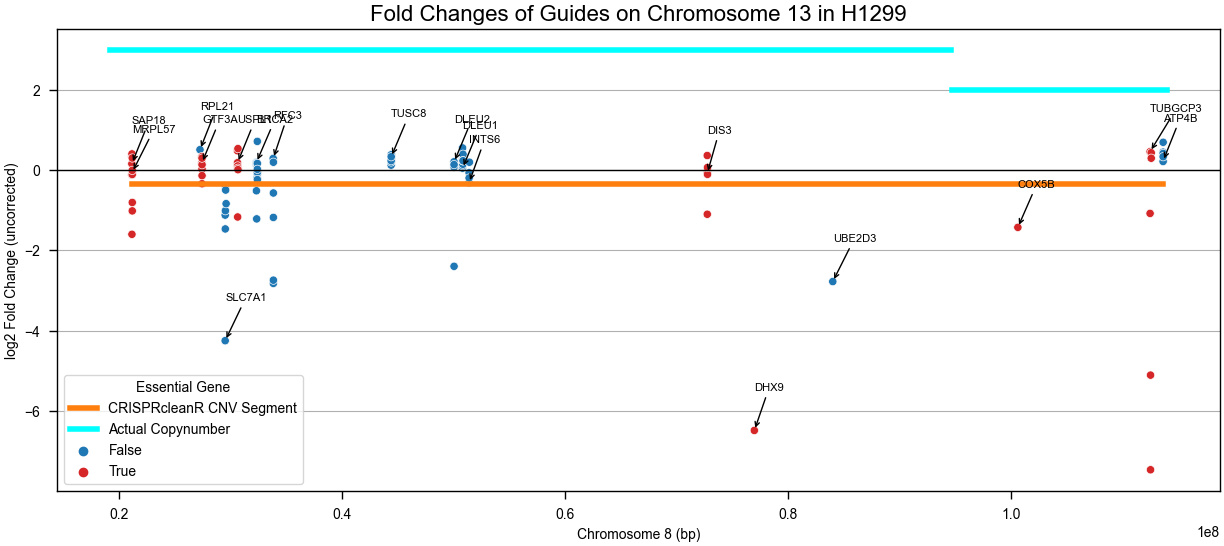

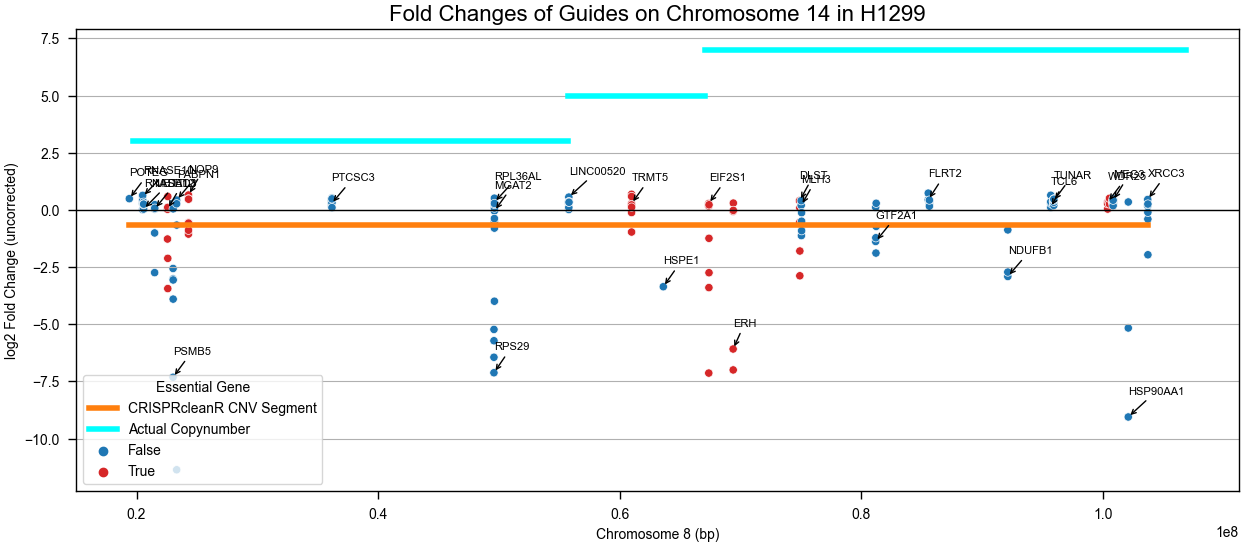

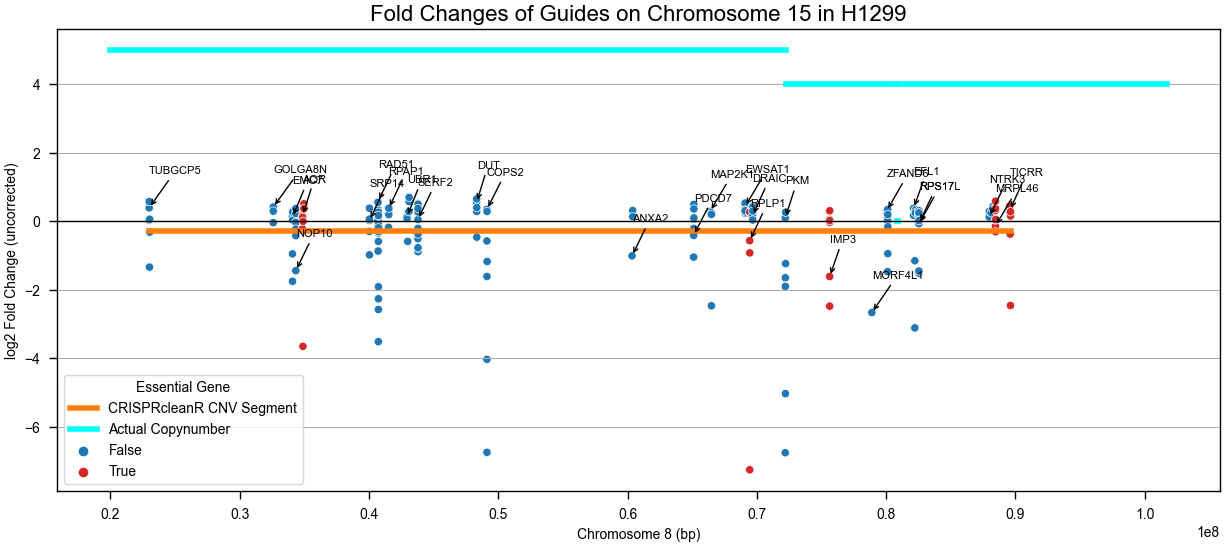

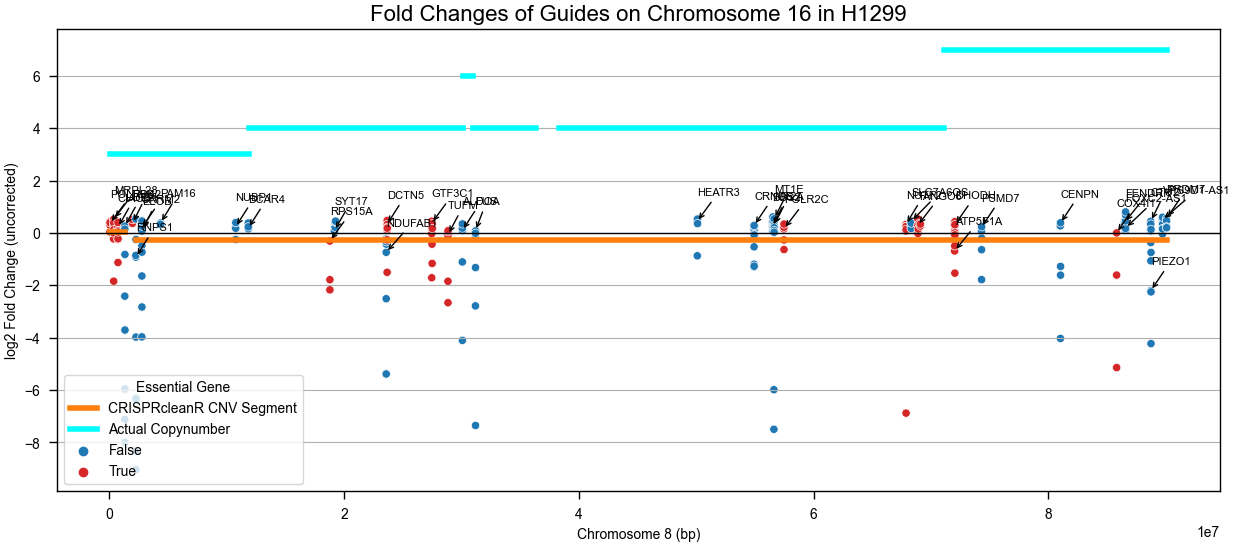

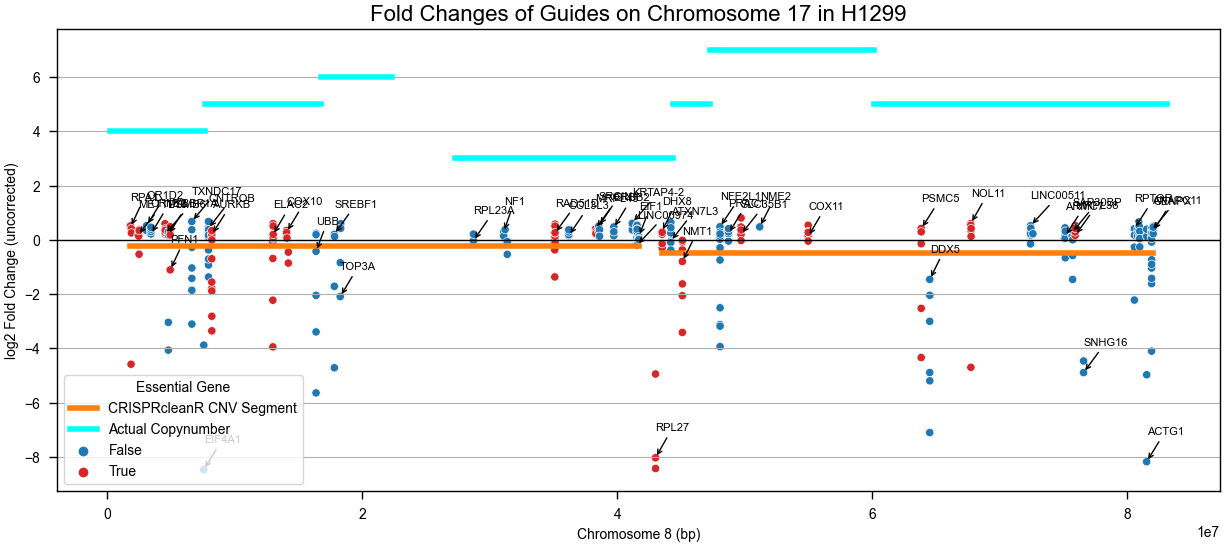

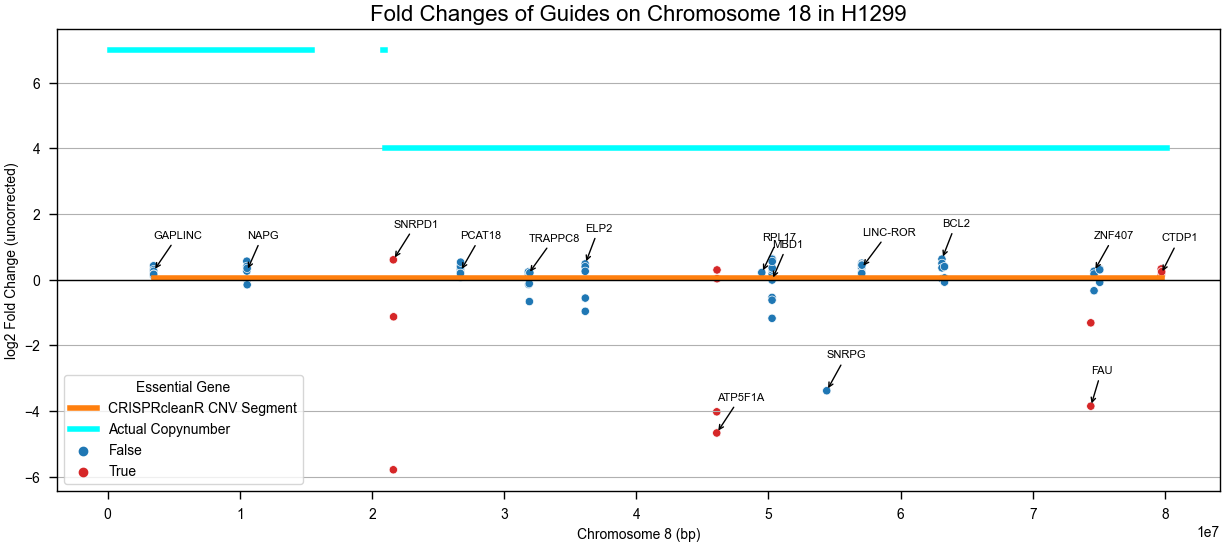

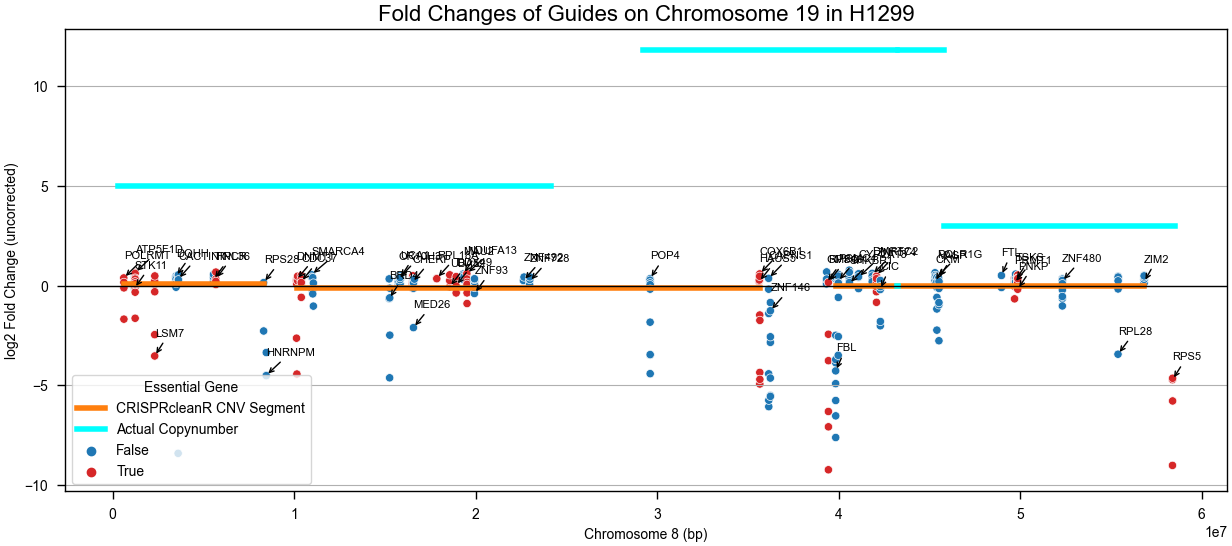

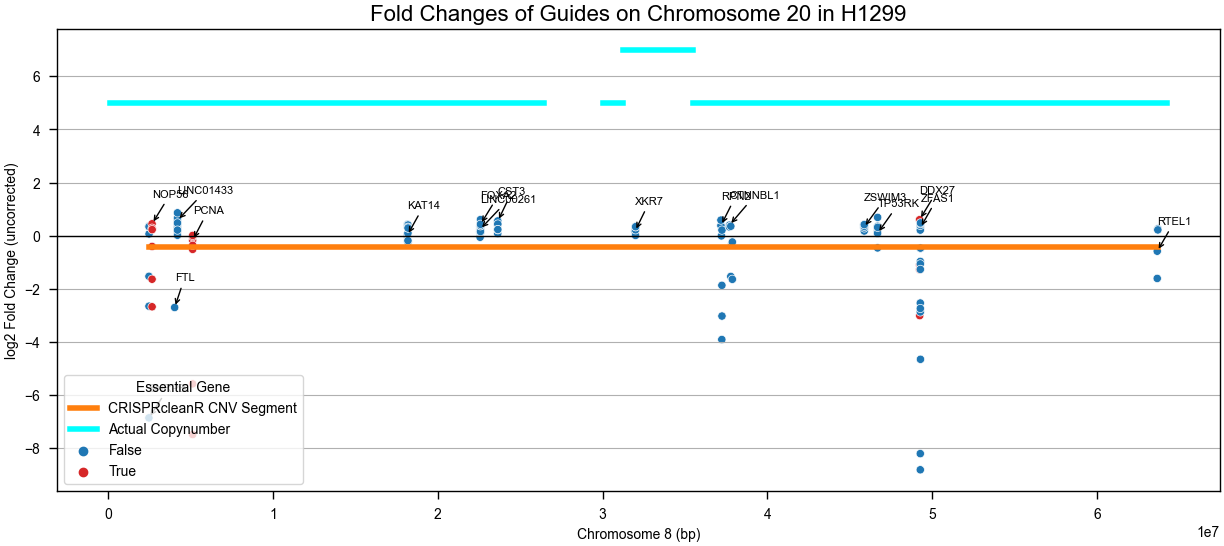

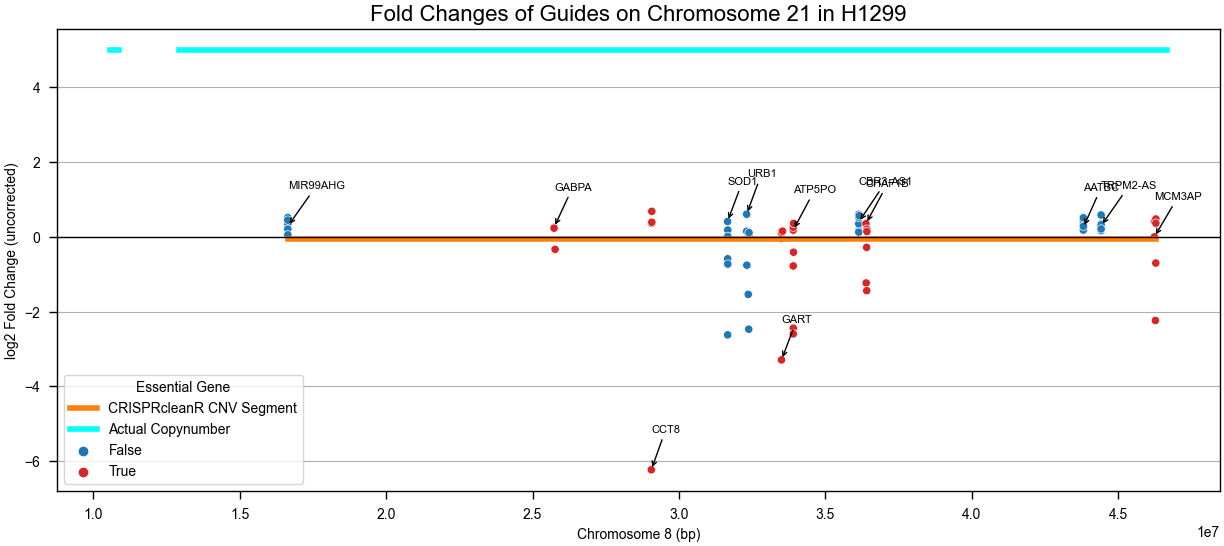

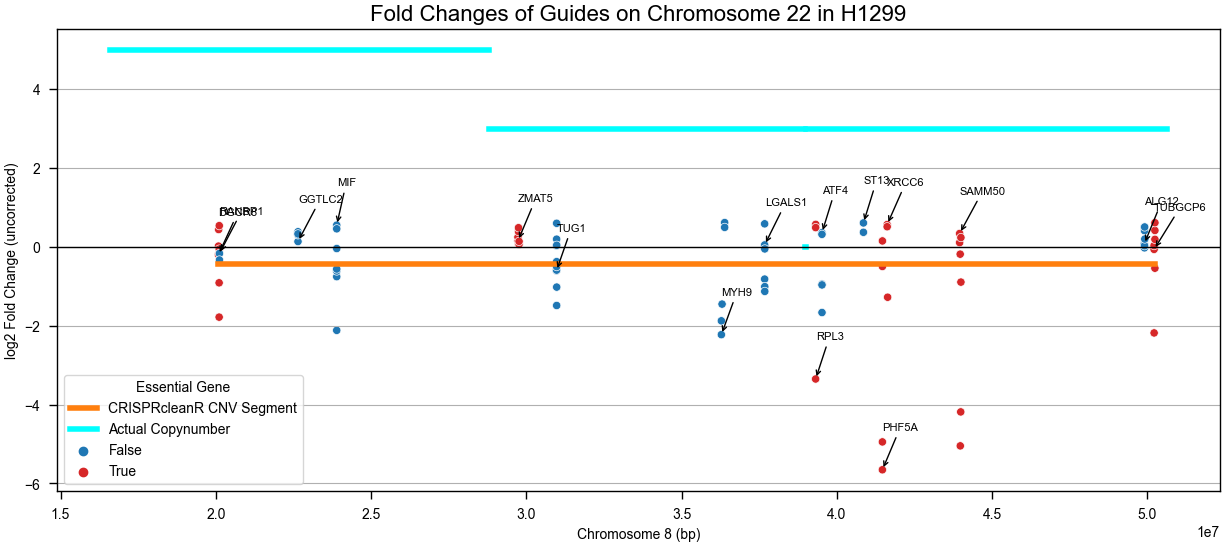

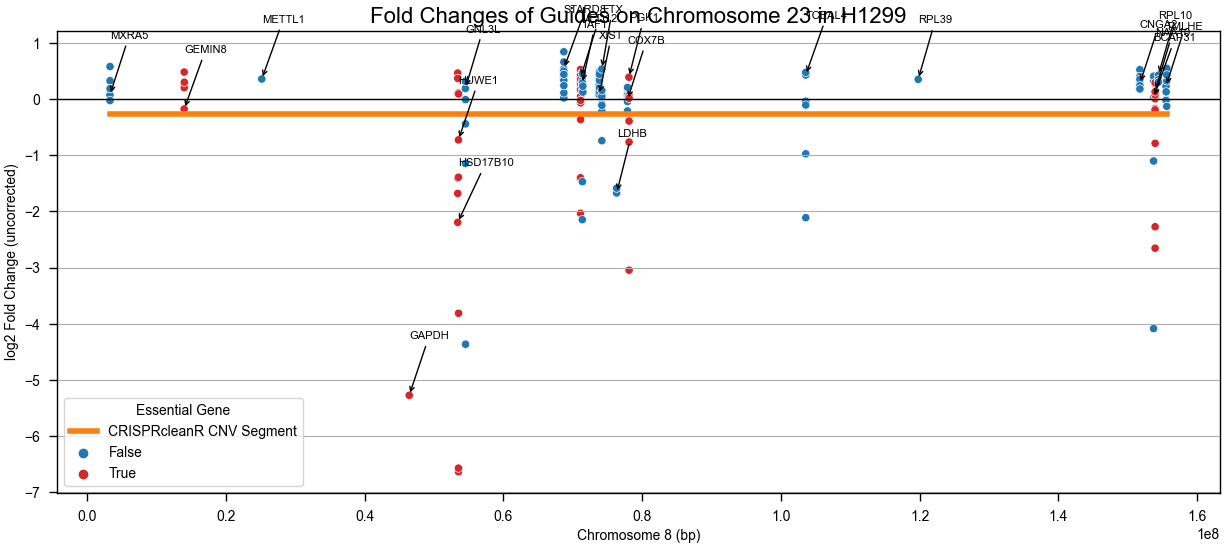

In [29]:
from matplotlib.backends.backend_pdf import PdfPages
import os
os.makedirs('../results/copynumber', exist_ok=True)
fc_data = pd.read_csv(f'/scratch/peidli/SYMPHONY/pooled_screen_1/crisprcleanr/{cell_line}_corrected_logFCs.csv', index_col=0)
with PdfPages(f'../results/copynumber/CNE_profiles_linear_{cell_line}.pdf') as pdf:
    for chrom in tqdm(np.arange(1,24)):
        fig, ax = pl.subplots(figsize=(15, 6))
        # CCR CNV segments
        df = ccr_segments[ccr_segments.CHR == chrom]
        for i, row in df.iterrows():
            start, end = row['startp'], row['endp']
            y = row['avg.logFC']
            pl.plot([start, end], [y, y], 'tab:orange', linewidth=4, label='CRISPRcleanR CNV Segment' if i == df.index[0] else None)
            
        # Ground truth CNV segments
        df = cnv_segments[cnv_segments.chr_name == f'chr{chrom}']
        for i, row in df.iterrows():
            start, end = row['chr_start'], row['chr_end']
            y = row['total_copy_number']
            pl.plot([start, end], [y, y], 'cyan', linewidth=4, label='Actual Copynumber' if i == df.index[0] else None)

        # Foldchanges uncorrected
        df = fc_data[fc_data.CHR == chrom]
        # I should mark known essential genes
        essential = pd.read_csv("../resources/bagel_supplement/CEGv2.txt", sep='\t', index_col=0)
        non_essential = pd.read_csv("../resources/bagel_supplement/NEGv1.txt", sep='\t', index_col=0)
        df['gene'] = df.index.str.split('_').str[0]
        df['essential'] = df.gene.isin(essential.index)
        sns.scatterplot(data=df, x='startp', y='avgFC', ax=ax, hue='essential', palette={True: 'tab:red', False: 'tab:blue'})
        
        # names
        unique_names = []
        for i, row in df.iterrows():
            if row['gene'] in unique_names:
                continue
            pl.annotate(row['gene'], (row['startp'], row['avgFC']), (row['startp'], row['avgFC']+1), 
                        fontsize=8, arrowprops=dict(arrowstyle='->'))
            unique_names.append(row['gene'])

        ax.axhline(0, color='black', linewidth=1)
        pl.legend(title='Essential Gene', loc='lower left')
        pl.ylabel('log2 Fold Change (uncorrected)')
        pl.xlabel('Chromosome 8 (bp)')
        pl.grid(axis='y')
        pl.title(f'Fold Changes of Guides on Chromosome {chrom} in {cell_line}', fontsize=16)
        pdf.savefig(bbox_inches='tight')
        pl.show()

# Data driven CNE testing

In [57]:
# Does the GT CN correlate with avg logFC?

In [59]:
# Ground truth CNV segments
cnv_segments = pd.read_csv(f'../resources/CNV_profiles/{cell_line}_pureCN_CNV_segments.csv')
df_ = cnv_segments.copy()
# Foldchanges uncorrected
fc_data = pd.read_csv(f'/scratch/peidli/SYMPHONY/pooled_screen_1/crisprcleanr/{cell_line}_corrected_logFCs.csv', index_col=0)
df = fc_data.copy()
# I should mark known essential genes
essential = pd.read_csv("../resources/bagel_supplement/CEGv2.txt", sep='\t', index_col=0)
non_essential = pd.read_csv("../resources/bagel_supplement/NEGv1.txt", sep='\t', index_col=0)
df['gene'] = df.index.str.split('_').str[0]
df['essential'] = df.gene.isin(essential.index)

In [83]:
# add copynumber to all genes in each segment
df['total_copy_number'] = 2  # I assume this is how the data works, not much info given with file
for i, row in df_.iterrows():
    start, end = row['chr_start'], row['chr_end']
    gene_on_chromosome = row.chr_name == np.array([f'chr{chrom}' for chrom in df.CHR])
    gene_in_segment = (df.startp >= start) & (df.startp <= end)
    df['total_copy_number'][gene_in_segment & gene_on_chromosome] = row['total_copy_number']
df['total_copy_number'] = df['total_copy_number'].astype(int)

False: slope=-0.061, intercept=0.024, r_value=-0.079, p_value=0.000, std_err=0.013
slope (95%): -0.061 +/- 0.025
intercept (95%): 0.024 +/- 0.134
True: slope=-0.094, intercept=-0.218, r_value=-0.087, p_value=0.001, std_err=0.031
slope (95%): -0.094 +/- 0.060
intercept (95%): -0.218 +/- 0.303


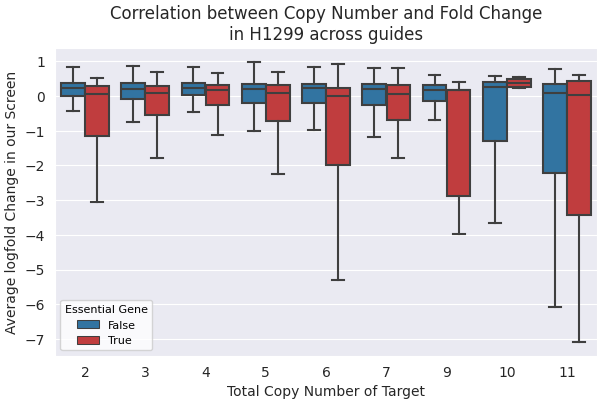

In [112]:
with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(7, 4))
palette = {True: 'tab:red', False: 'tab:blue'}
sns.boxplot(data=df, x='total_copy_number', y='avgFC', hue='essential', palette=palette, showfliers=False)
# add regression lines for each hue
from scipy.stats import linregress
for hue in df.essential.unique():
    x, y = df[df.essential == hue]['total_copy_number'], df[df.essential == hue]['avgFC']
    res = linregress(x, y, alternative='less')
    slope, intercept, r_value, p_value, std_err = res
    print(f'{hue}: slope={slope:.3f}, intercept={intercept:.3f}, r_value={r_value:.3f}, p_value={p_value:.3f}, std_err={std_err:.3f}')
    
    # Calculate 95% confidence interval on slope and intercept:
    # Two-sided inverse Students t-distribution
    # p - probability, df - degrees of freedom
    from scipy.stats import t
    tinv = lambda p, df: abs(t.ppf(p/2, df))
    ts = tinv(0.05, len(x)-2)
    print(f"slope (95%): {res.slope:.3f} +/- {ts*res.stderr:.3f}")
    print(f"intercept (95%): {res.intercept:.3f}"
        f" +/- {ts*res.intercept_stderr:.3f}")
    
pl.legend(fontsize=8, title='Essential Gene', title_fontsize=8)
pl.xlabel('Total Copy Number of Target')
pl.ylabel('Average logfold Change in our Screen')
pl.title(f'Correlation between Copy Number and Fold Change\nin {cell_line} across guides')
pl.show()

In [123]:
# TODO: I should also test a Cas9 screen
# https://github.com/francescojm/CRISPRcleanR/blob/master/inst/extdata/HT29-Brunello_counts.tsv
bdf = pd.read_csv('../resources/HT29-Brunello_counts.tsv', sep='\t', index_col=0)
controls = bdf.index[bdf.index.str.contains('Control')]
sample_names = ['Brunello_plasmid', 'Brunello_HT29-rep1', 'Brunello_HT29-rep2', 'Brunello_HT29-rep3']
pools = ['Brunello_plasmid']